## Five-Driver Taxi Operating Patterns (Flag 6)

### Dataset Overview
Twelve completed tasks are provided for each of five Porto taxi drivers. The data include task order, local origin and destination coordinates, timestamps, driver shifts, long idle windows, taxi-stand locations, and timestamped route points.

The notebook exposes a primary table and a supporting table (`trajectory_points.csv`).

Goal: Study the driving and task-acceptance behavior of five drivers using their multiple provided trajectories.

Role: Urban taxi operations analyst


Category: Multi-driver operating behavior

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "completed_tasks.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "trajectory_points.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: Do drivers generally finish a local sequence of tasks before moving to another service area?

#### Analysis action

Inspect the event sequence, locations, and operating intervals together rather than treating each trip independently.

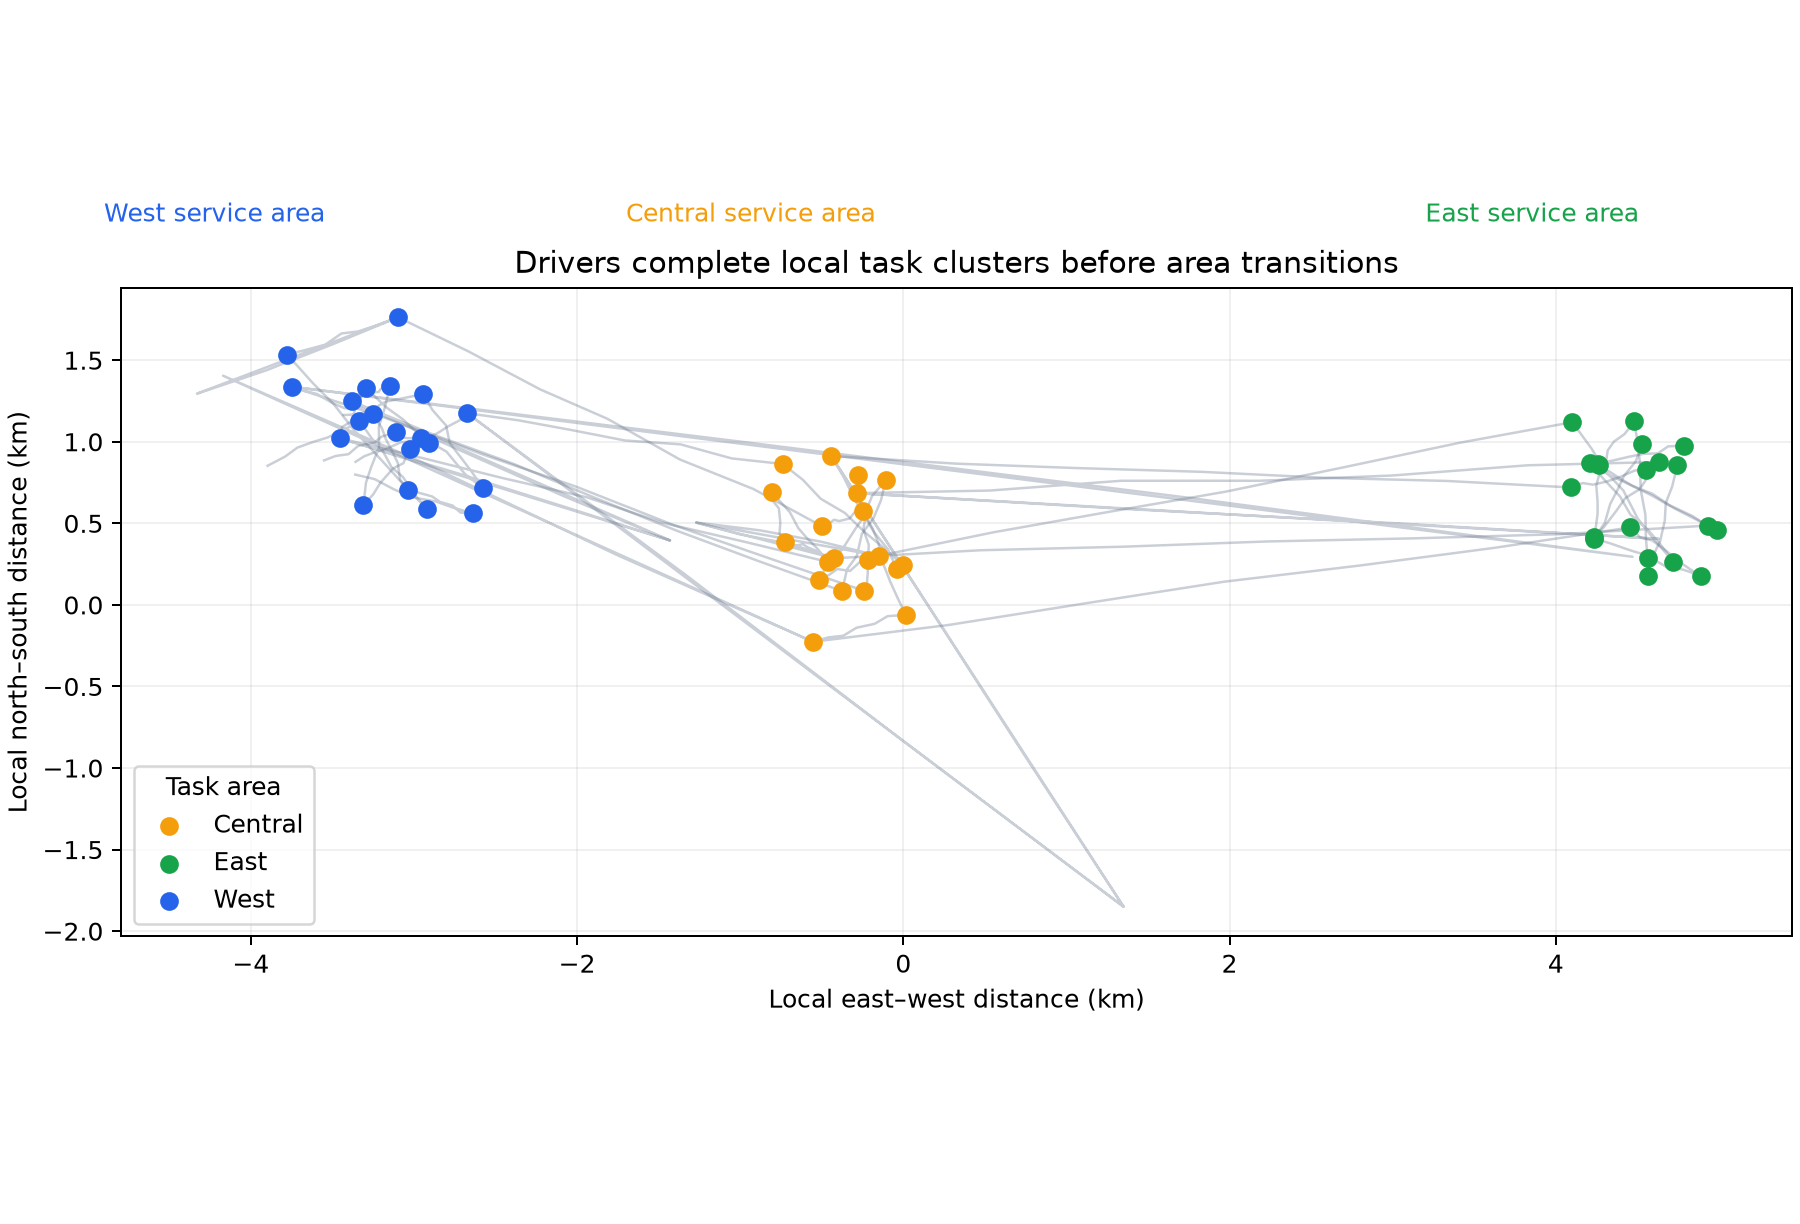

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
d=df.sort_values(['driver_id','completion_sequence']); print(d.groupby('driver_id').service_area.apply(list)); plt.scatter(d.destination_x_km,d.destination_y_km,c=pd.Categorical(d.service_area).codes); plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/area_sequence_routes.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "spatial_sequence",
  "insight": "Most drivers complete tasks within one service area before moving to the next area; for example, they spend an extended sequence in the west before transitioning eastward to continue accepting tasks.",
  "insight_value": {
    "drivers_with_clustered_area_sequence": 5,
    "within_area_runs_before_transition": 3
  },
  "plot": {
    "plot_type": "spatial_sequence",
    "title": "Area-Ordered Task Sequences",
    "file": "visualizations/area_sequence_routes.png",
    "description": "Task destinations are colored by service area and gray lines show the five full driver routes."
  },
  "question": "Do drivers generally finish a local sequence of tasks before moving to another service area?",
  "actionable_insight": "Inspect the event sequence, locations, and operating intervals together rather than treating each trip independently.",
  "code": "import pandas as pd\nimport matplotlib.pyplot as plt\nd=df.sort_values(['driver_id','completion_sequence']); print(d.groupby('driver_id').service_area.apply(list)); plt.scatter(d.destination_x_km,d.destination_y_km,c=pd.Categorical(d.service_area).codes); plt.show()",
  "insight_type": "temporal_dynamics",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "driver_id",
    "gps_position",
    "completion_time",
    "trajectory_id"
  ]
}

### **Question 2**: Do extended idle windows tend to occur after batches of consecutive tasks?

#### Analysis action

Inspect the event sequence, locations, and operating intervals together rather than treating each trip independently.

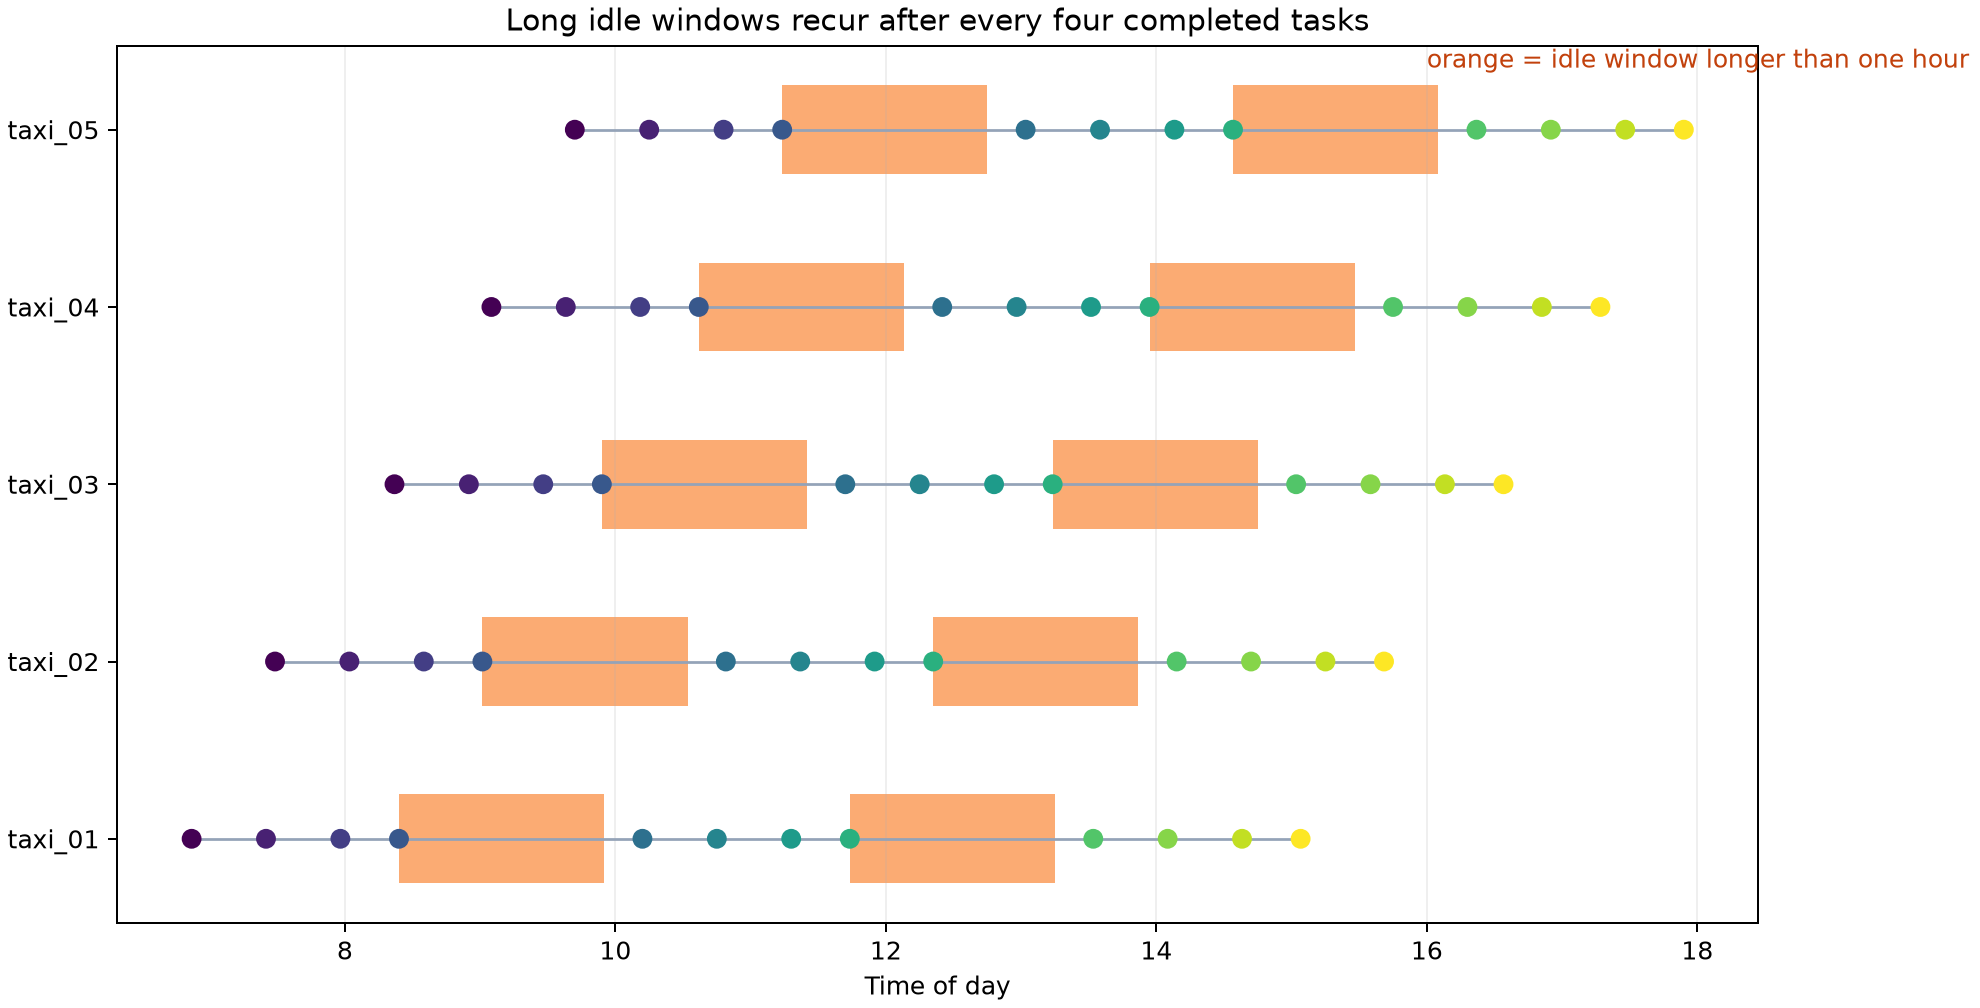

In [ ]:
import pandas as pd
d=df[df.next_gap_minutes>0]; print(d[['driver_id','completion_sequence','next_gap_minutes']]); print(d.groupby('completion_sequence').next_gap_minutes.median())
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/four_task_idle_windows.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "temporal_sequence",
  "insight": "Drivers commonly experience extended idle windows after completing a batch of consecutive tasks.",
  "insight_value": {
    "long_idle_windows": 10,
    "median_minutes": 91.0
  },
  "plot": {
    "plot_type": "temporal_sequence",
    "title": "Long Idle Windows after Four Tasks",
    "file": "visualizations/four_task_idle_windows.png",
    "description": "Completed-task timelines show long orange idle intervals after the fourth and eighth completed task for each driver."
  },
  "question": "Do extended idle windows tend to occur after batches of consecutive tasks?",
  "actionable_insight": "Inspect the event sequence, locations, and operating intervals together rather than treating each trip independently.",
  "code": "import pandas as pd\nd=df[df.next_gap_minutes>0]; print(d[['driver_id','completion_sequence','next_gap_minutes']]); print(d.groupby('completion_sequence').next_gap_minutes.median())",
  "insight_type": "temporal_dynamics",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "driver_id",
    "completion_time",
    "trajectory_id",
    "request_time"
  ]
}

### **Question 3**: Where do the drivers spend their long idle windows, and are those locations typically taxi stands?

#### Analysis action

Inspect the event sequence, locations, and operating intervals together rather than treating each trip independently.

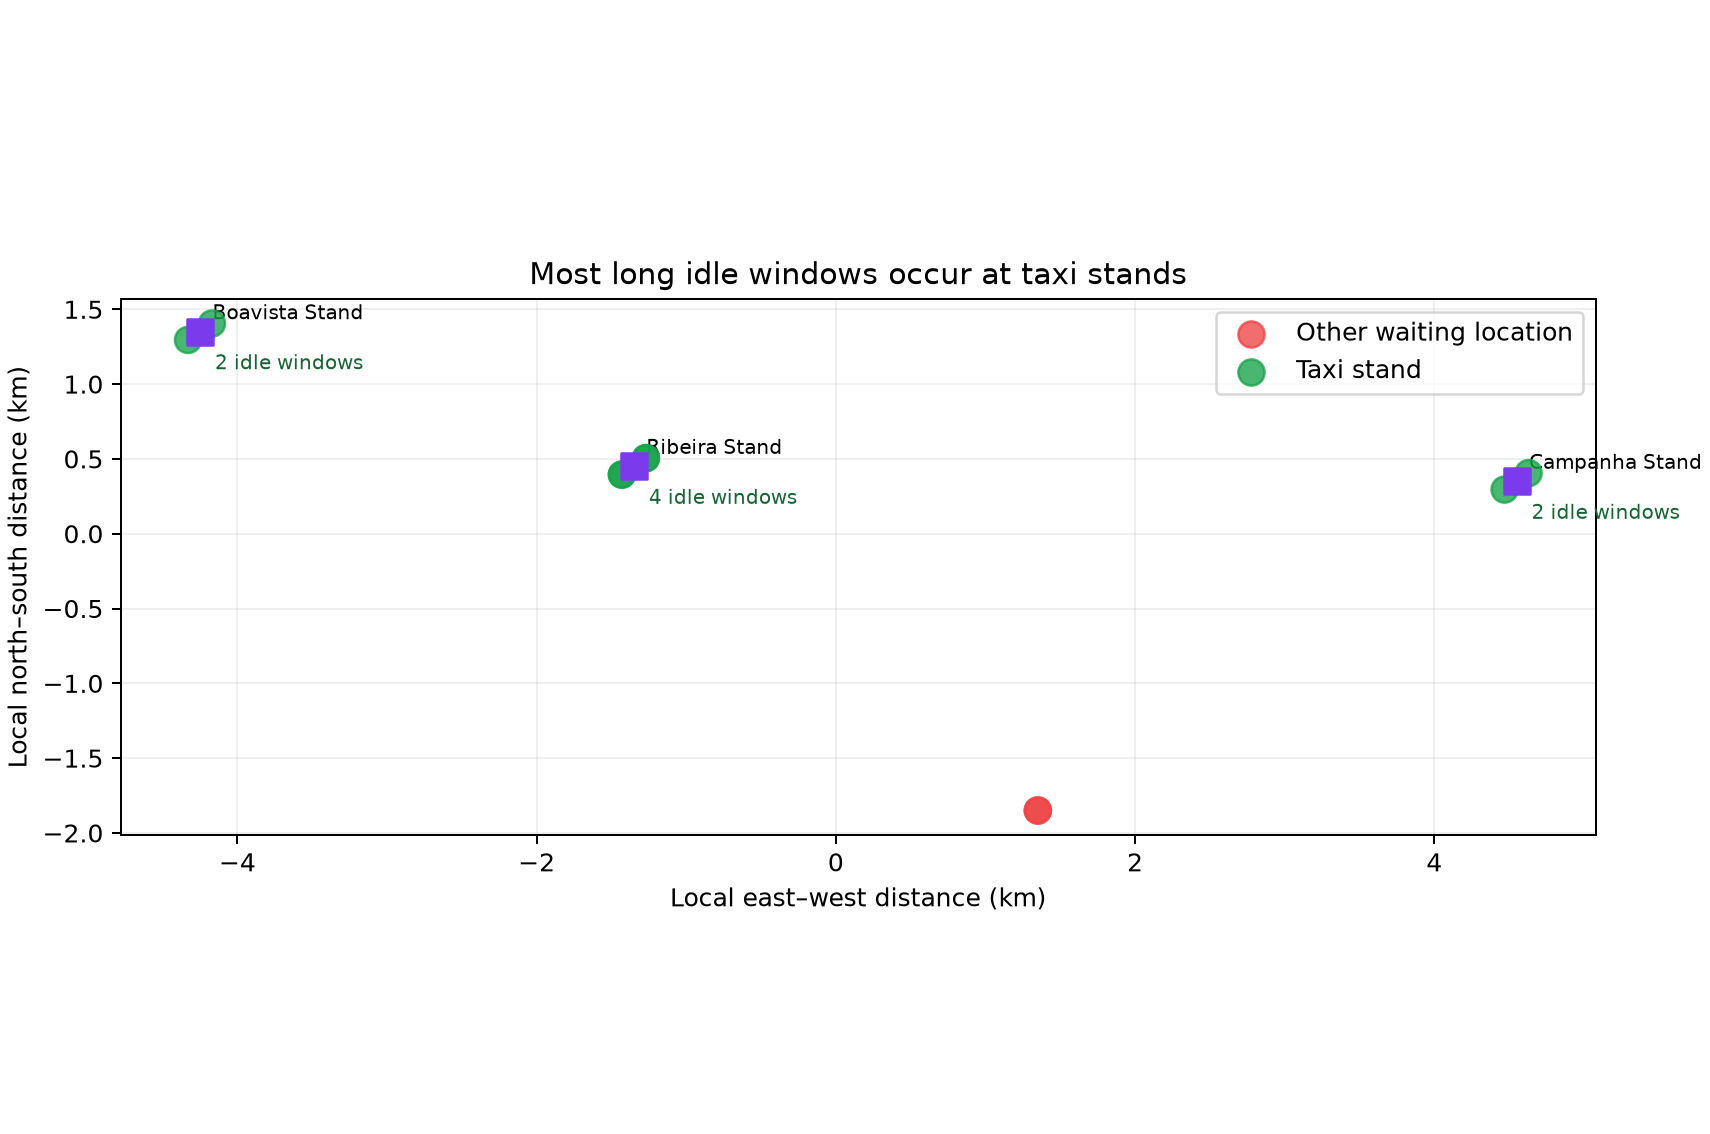

In [ ]:
import pandas as pd
d=pd.read_csv('idle_windows.csv'); print(pd.crosstab(d.location_type,d.after_completion_sequence)); print(d.groupby('location_type').duration_minutes.agg(['count','median']))
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/idle_window_locations.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (6 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "spatial_temporal_association",
  "insight": "During these idle windows, the drivers usually, though not always, wait at a taxi stand.",
  "insight_value": {
    "idle_windows_at_taxi_stand": 8,
    "all_long_idle_windows": 10
  },
  "plot": {
    "plot_type": "spatial_temporal_association",
    "title": "Locations of Long Idle Windows",
    "file": "visualizations/idle_window_locations.png",
    "description": "Purple squares are taxi stands; circle size encodes idle-window duration and color distinguishes stand from non-stand waiting."
  },
  "question": "Where do the drivers spend their long idle windows, and are those locations typically taxi stands?",
  "actionable_insight": "Inspect the event sequence, locations, and operating intervals together rather than treating each trip independently.",
  "code": "import pandas as pd\nd=pd.read_csv('idle_windows.csv'); print(pd.crosstab(d.location_type,d.after_completion_sequence)); print(d.groupby('location_type').duration_minutes.agg(['count','median']))",
  "insight_type": "factor_relationship",
  "difficulty_level": 6,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "completion_time",
    "driver_id",
    "trajectory_id",
    "request_time",
    "gps_position",
    "stand_position"
  ]
}

### **Question 4**: How do the five drivers' start times and total operating durations compare?

#### Analysis action

Inspect the event sequence, locations, and operating intervals together rather than treating each trip independently.

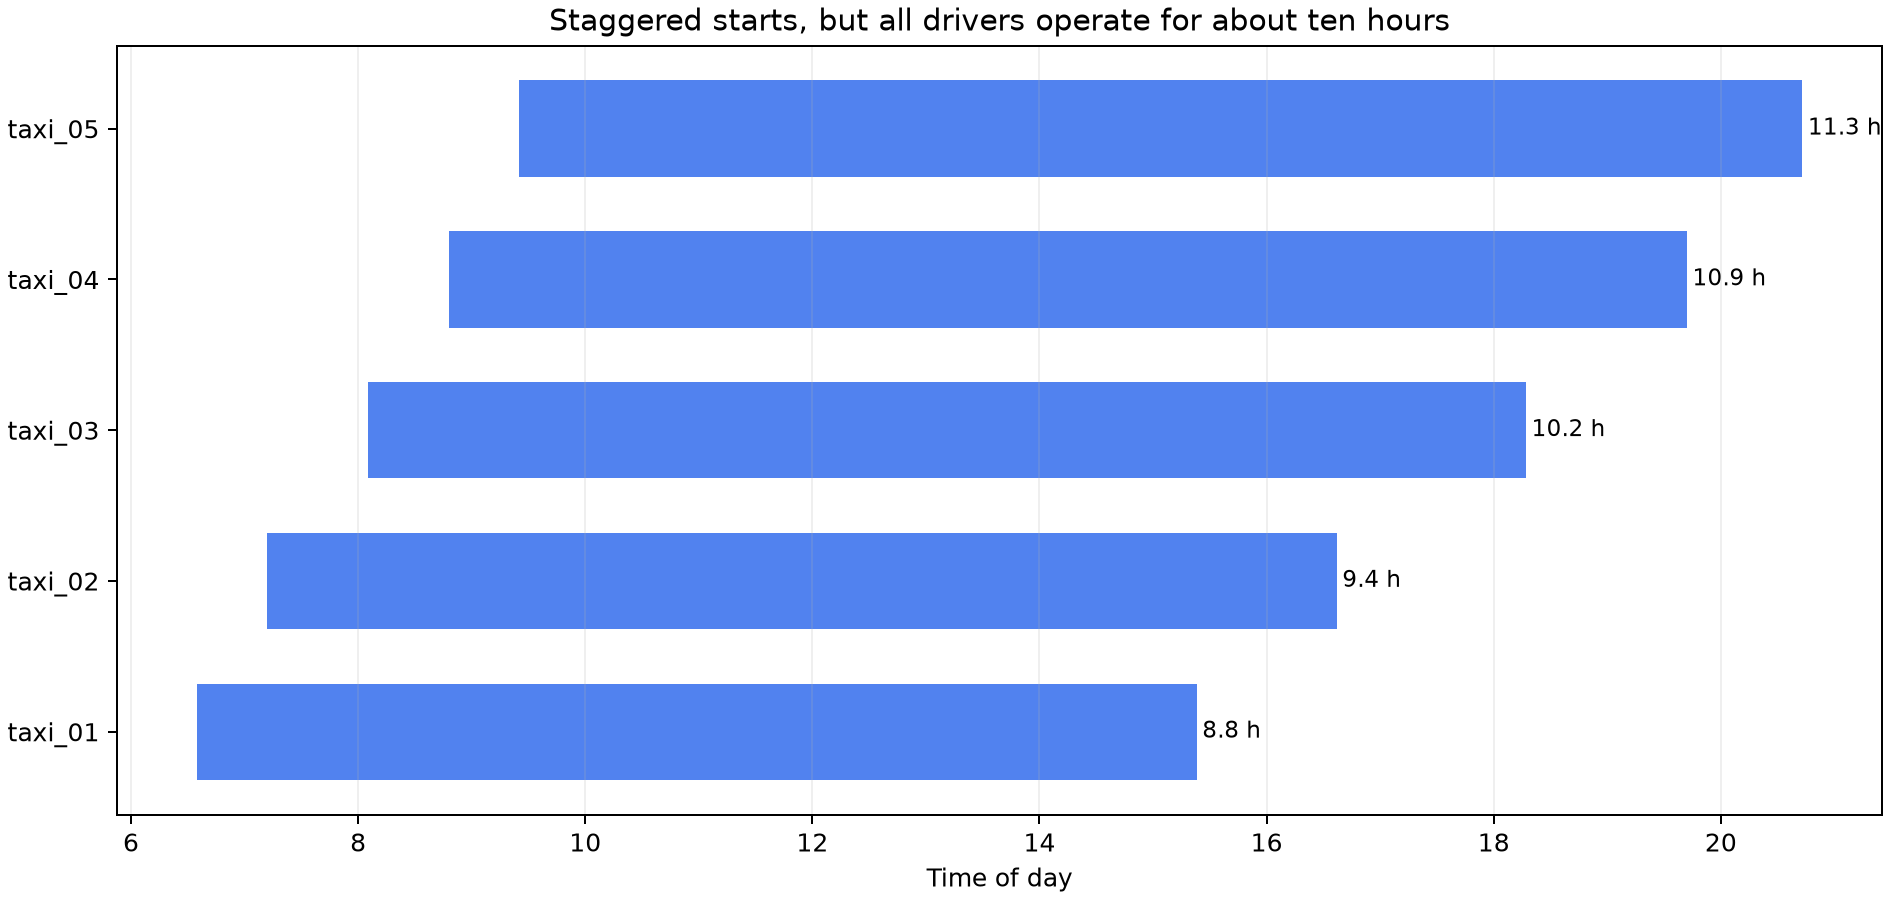

In [ ]:
import pandas as pd
d=pd.read_csv('driver_shifts.csv'); print(d[['driver_id','shift_start','shift_end','shift_duration_hours']])
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/driver_shift_durations.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "shift_comparison",
  "insight": "The five drivers begin work at different times, but each works for approximately ten hours.",
  "insight_value": {
    "earliest_start": "06:35",
    "latest_start": "09:25",
    "duration_range_hours": [
      8.8,
      11.3
    ]
  },
  "plot": {
    "plot_type": "shift_comparison",
    "title": "Staggered Driver Shifts",
    "file": "visualizations/driver_shift_durations.png",
    "description": "Each horizontal bar is one observed driver shift, positioned by time of day and labeled with its duration."
  },
  "question": "How do the five drivers' start times and total operating durations compare?",
  "actionable_insight": "Inspect the event sequence, locations, and operating intervals together rather than treating each trip independently.",
  "code": "import pandas as pd\nd=pd.read_csv('driver_shifts.csv'); print(d[['driver_id','shift_start','shift_end','shift_duration_hours']])",
  "insight_type": "group_comparison",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "driver_id",
    "request_time",
    "shift_end_time"
  ]
}

### Summary of Findings (Flag 6)

Across the five drivers, completed tasks are predominantly organized as consecutive within-area sequences before a transition to the next service area. Their workloads contain extended idle windows between consecutive task batches; most of these windows are spent at a taxi stand. Despite staggered starts, the five shifts are all close to ten hours long.